# 04 — Pesquisa local: Hill Climbing e Simulated Annealing

Experiências detalhadas da pesquisa local (`src/local_search.py`):

* tamanho e composição da vizinhança;
* Hill Climbing *steepest* vs. *first improvement*, com curvas de custo por iteração;
* Simulated Annealing: curvas e sensibilidade a T₀ e α;
* efeito da solução inicial (Greedy, CSP ou uma solução trivial inviável).

In [1]:
import sys, json, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from src.model import load_problem, evaluate, schedule_table, State, PICKUP, DELIVERY
from src.model import check_solution
from src.model import plot_routes, plot_gantt, plot_histories

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 170)
ROOT = Path.cwd().parent
REPORTS = ROOT / "reports"
RUN_HEAVY = False   # True: volta a correr as pesquisas longas em vez de ler reports/
tiny = load_problem(ROOT / "data" / "tiny")
small = load_problem(ROOT / "data" / "small")
PROBLEMS = {"tiny": tiny, "small": small}

from src.informed import greedy, h_mst
from src.local_search import hill_climbing, simulated_annealing, neighbours
from src.csp import solve
best = json.loads((REPORTS / "best.json").read_text())
starts = {ds: greedy(p, h_mst).solution for ds, p in PROBLEMS.items()}

## 1. Vizinhança

* *relocate*: tirar um pedido e pô-lo noutra posição, viagem ou veículo, ou numa viagem nova.
* *swap*: trocar dois pedidos do mesmo tipo.
* *2-opt*: inverter um segmento dentro de uma viagem.

Os movimentos nunca misturam recolhas e entregas na mesma viagem.

In [2]:
from collections import Counter
for ds, p in PROBLEMS.items():
    c = Counter(m[0] for m, _ in neighbours(p, starts[ds]))
    feas = sum(evaluate(p, n).feasible for _, n in neighbours(p, starts[ds]))
    print(ds, dict(c), "| total:", sum(c.values()), "| viáveis:", feas)

tiny {'relocate': 210, 'new-trip': 160, 'swap': 81, '2-opt': 18} | total: 469 | viáveis: 46
small {'relocate': 893, 'new-trip': 442, 'swap': 366, '2-opt': 67} | total: 1768 | viáveis: 155


## 2. Hill Climbing a partir do Greedy (h3)

In [3]:
hc = {}
for ds, p in PROBLEMS.items():
    hc[ds, "steepest"] = hill_climbing(p, starts[ds], "steepest")
    for seed in range(5):
        hc[ds, f"first-{seed}"] = hill_climbing(p, starts[ds], "first", seed=seed)
pd.DataFrame([dict(dataset=ds, variante=v, **r.summary()) for (ds, v), r in hc.items()])

,dataset,variante,algorithm,initial_km,final_km,improvement_pct,feasible,iterations,evaluated,seconds
0,tiny,steepest,HC-steepest,625.46,533.09,14.77,True,5,2714,0.127
1,tiny,first-0,HC-first,625.46,533.09,14.77,True,5,705,0.039
2,tiny,first-1,HC-first,625.46,533.09,14.77,True,5,1124,0.058
3,tiny,first-2,HC-first,625.46,533.09,14.77,True,5,834,0.043
4,tiny,first-3,HC-first,625.46,533.09,14.77,True,5,856,0.044
5,tiny,first-4,HC-first,625.46,533.09,14.77,True,5,590,0.036
6,small,steepest,HC-steepest,1000.35,799.35,20.09,True,8,15904,0.970
7,small,first-0,HC-first,1000.35,834.22,16.61,True,11,4420,0.451
8,small,first-1,HC-first,1000.35,799.35,20.09,True,14,5230,0.548
9,small,first-2,HC-first,1000.35,825.54,17.47,True,10,2844,0.358


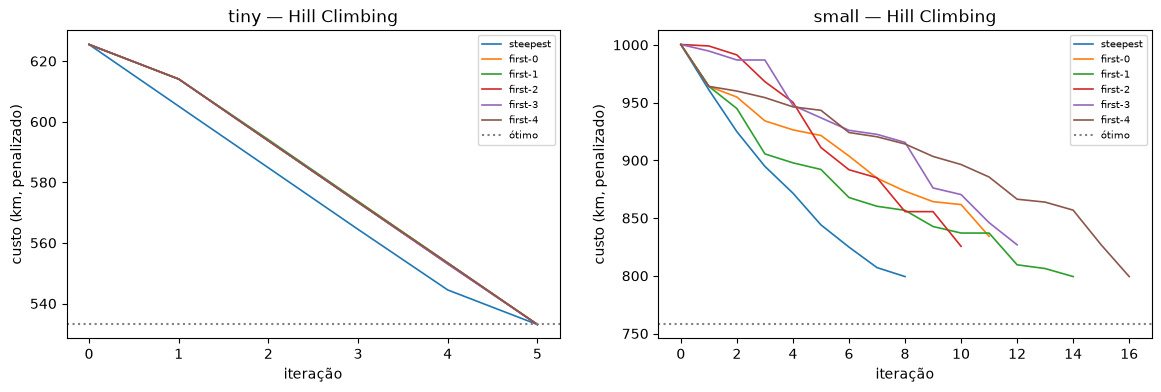

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a_, ds in zip(ax, PROBLEMS):
    plot_histories({v: dict(current=r.history) for (d, v), r in hc.items() if d == ds}, f"{ds} — Hill Climbing", ax=a_)
    a_.axhline(best[ds]["km"], color="grey", ls=":", label="ótimo"); a_.legend(fontsize=7)

In [5]:
for ds in PROBLEMS:
    print(ds, "movimentos aceites (steepest):", [m[0] for m in hc[ds, "steepest"].moves])

tiny movimentos aceites (steepest): ['relocate', 'relocate', 'relocate', 'swap', 'relocate']
small movimentos aceites (steepest): ['relocate', 'relocate', 'relocate', 'relocate', 'relocate', 'relocate', 'relocate', 'relocate']


O *steepest* escolhe sempre o melhor vizinho. Faz poucas iterações, mas cada uma avalia a vizinhança
toda. O *first improvement* aceita o primeiro vizinho que melhora, por isso cada iteração é mais barata
e são precisas mais. Como a ordem é aleatória, cada semente pode acabar num ótimo local diferente.

## 3. Simulated Annealing

,dataset,algorithm,initial_km,final_km,improvement_pct,feasible,iterations,evaluated,seconds
0,tiny,SA,625.46,533.09,14.77,True,30000,30000,1.189
1,small,SA,1000.35,771.69,22.86,True,30000,30000,1.959


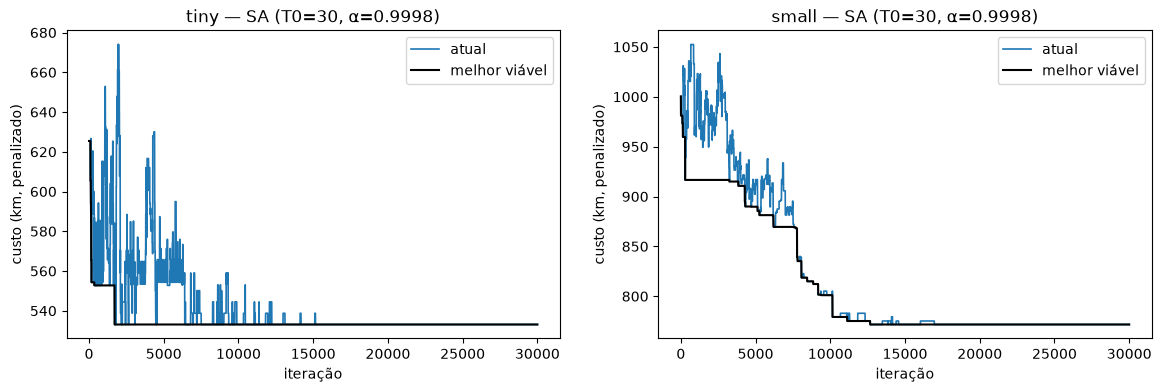

In [6]:
sa = {ds: simulated_annealing(p, starts[ds], t0=30, alpha=0.9998, iters=30_000, seed=0) for ds, p in PROBLEMS.items()}
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a_, ds in zip(ax, PROBLEMS):
    plot_histories({"atual": dict(current=sa[ds].history)}, f"{ds} — SA (T0=30, α=0.9998)", ax=a_, cap=best[ds]["km"] * 1.6)
    ys = pd.Series(sa[ds].best_history).replace(float("inf"), None)
    a_.plot(ys.index, ys.values, color="black", lw=1.5, label="melhor viável"); a_.legend()
pd.DataFrame([dict(dataset=ds, **r.summary()) for ds, r in sa.items()])

### Sensibilidade a T₀ e α (small, 3 sementes, 15 000 iterações)

A temperatura inicial T₀ controla quanto se aceitam pioras no início. O α controla a velocidade de
arrefecimento: com α = 0,9995, ao fim de 15 000 iterações T ≈ T₀ · 0,0006.

In [7]:
rows = []
for t0 in (5, 30, 100):
    for alpha in (0.999, 0.9995, 0.9998):
        for seed in range(3):
            r = simulated_annealing(small, starts["small"], t0=t0, alpha=alpha, iters=15_000, seed=seed)
            rows.append(dict(T0=t0, alpha=alpha, seed=seed, km=r.cost, viavel=r.feasible, segundos=r.seconds))
sens = pd.DataFrame(rows)
sens.pivot_table(index="T0", columns="alpha", values="km", aggfunc=["mean", "min"]).round(1)

mean                  min              
alpha 0.9990 0.9995 0.9998 0.9990 0.9995 0.9998
T0                                             
5      822.1  818.7  806.1  815.4  815.4  787.7
30     813.5  825.8  797.7  799.4  825.8  771.7
100    813.1  817.8  837.5  787.7  810.5  817.5

## 4. Efeito da solução inicial (small)

In [8]:
csp_start = solve(small, global_fc=True).solution
trivial = {v.vid: [] for v in small.vehicles}
for i, r in enumerate(sorted(small.requests, key=lambda r: small.requests[r].tw[0])):
    trivial[small.vehicles[i % 2].vid].append([r])
rows = []
for name, st in [("Greedy h3", starts["small"]), ("CSP (MAC+MRV+FC global)", csp_start), ("trivial (1 pedido por viagem)", trivial)]:
    e0 = evaluate(small, st)
    h = hill_climbing(small, st, "steepest") if e0.feasible else None
    s_ = simulated_annealing(small, st, t0=30, alpha=0.9998, iters=30_000, seed=0)
    rows.append(dict(inicio=name, km_inicial=round(e0.km, 2), inicial_viavel=e0.feasible,
                     HC_steepest=None if h is None else round(h.cost, 2), SA=round(s_.cost, 2) if s_.feasible else None))
pd.DataFrame(rows)

,inicio,km_inicial,inicial_viavel,HC_steepest,SA
0,Greedy h3,1000.35,True,799.35,771.69
1,CSP (MAC+MRV+FC global),860.72,True,785.50,811.92
2,trivial (1 pedido por viagem),1753.98,False,NaN,798.11


A solução trivial é inviável: tem atrasos e excede a permanência. O Hill Climbing não parte dela, porque
só se move entre soluções viáveis. O SA, que caminha pelo custo penalizado, consegue **reparar** a
solução e devolver uma viável. A solução inicial influencia bastante o ótimo local a que o HC chega: 799,35 km a partir do Greedy,
785,50 km a partir do CSP.

## 5. Melhor solução encontrada no small

SA {'km': 771.69, 'feasible': True, 'trips': 9, 'late_min': 0.0, 'over_kg': 0.0, 'dwell_excess_min': 0.0, 'unserved': 0, 'deadlock': 0, 'overnight': 0, 'makespan_min': 2456.5, 'route_min': 1440.3} | verificador por linha: True


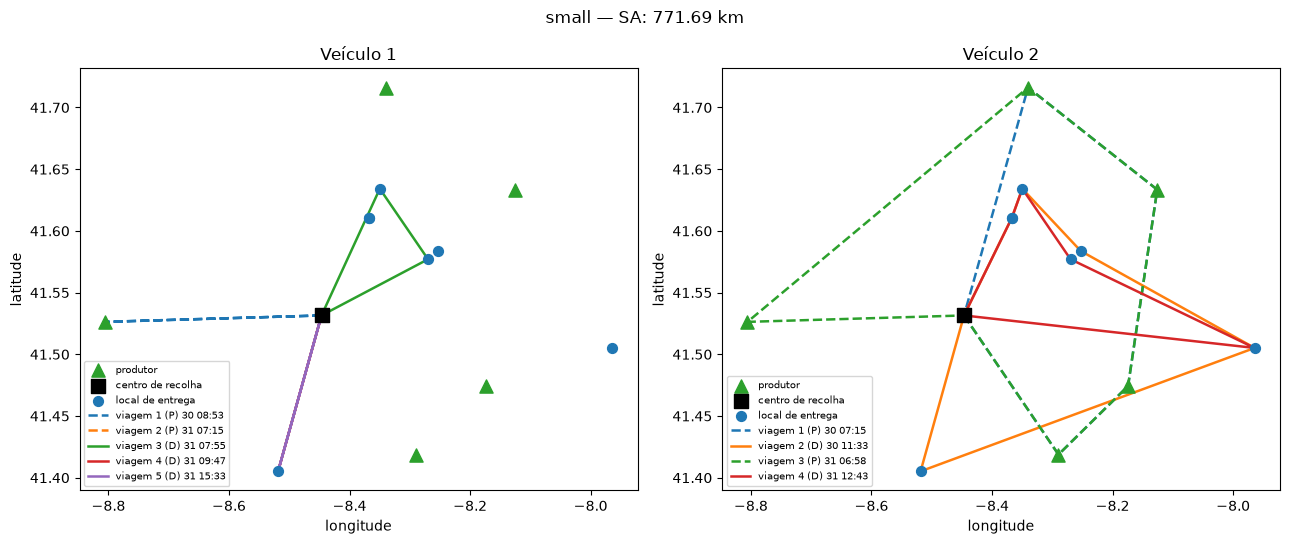

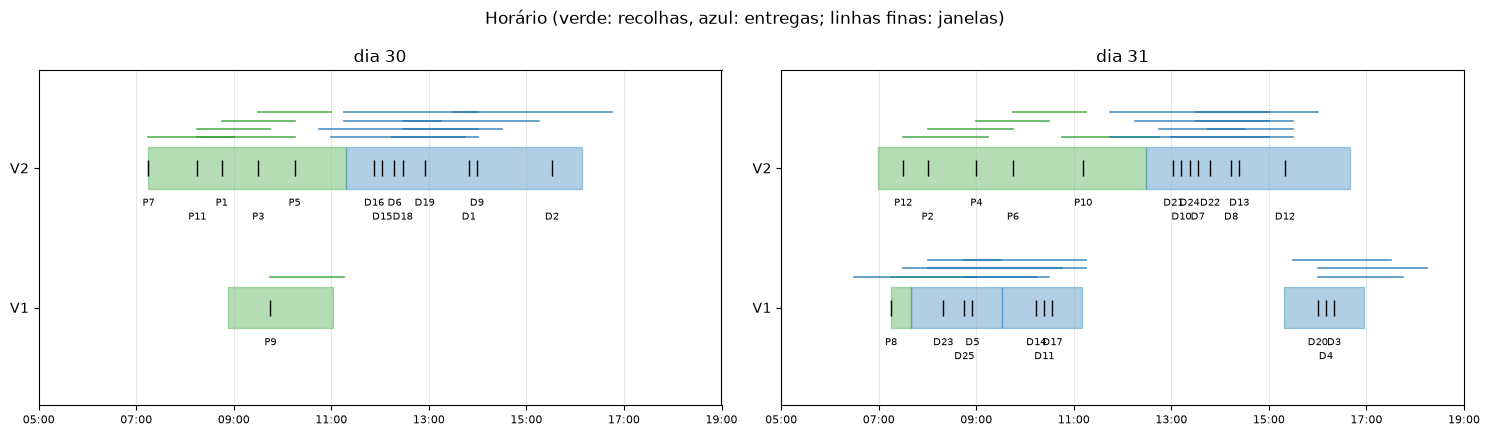

In [9]:
cands = [(r.cost, f"HC {v}", r.solution) for (ds, v), r in hc.items() if ds == "small" and r.feasible]
cands.append((sa["small"].cost, "SA", sa["small"].solution))
km_, name_, sol_ = min(cands, key=lambda c: c[0])
ev = evaluate(small, sol_)
print(name_, ev.summary(), "| verificador por linha:", check_solution(small, ev).valid)
plot_routes(small, sol_, f"small — {name_}: {ev.km:.2f} km");
plot_gantt(small, ev);

## 6. Conclusões

* No **tiny**, tanto o HC como o SA chegam ao ótimo (o mesmo valor provado pelo A\*): o HC em décimas de
  segundo, o SA em cerca de 1,2 s.
* No **small**, o ótimo provado pelo A\* por viagens é a referência (linha a tracejado). O HC
  *steepest* e algumas sementes do *first improvement* ficam presos num ótimo local acima dele. O SA
  depende muito de T₀, de α e da semente: explora mais, mas nem sempre bate o HC.
* O SA é útil para **reparar** soluções inviáveis. O HC precisa de uma solução viável para começar.
* O ponto de partida importa. Uma boa construção inicial (Greedy ou CSP), seguida de pesquisa local, é a
  combinação mais eficiente neste problema.